In [57]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

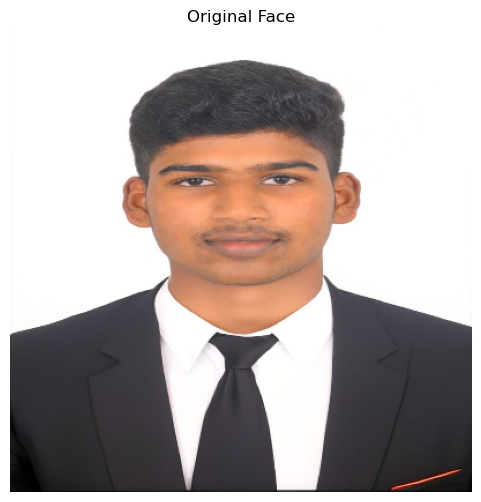

Face image dimensions: (400, 400, 3)


In [58]:
faceImage = cv2.imread('photo.JPG')

if faceImage is None:
    raise FileNotFoundError("Could not find 'photo.JPG'. Keep it in the notebook folder.")

resized_faceImage = cv2.resize(faceImage, (400, 400))

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(resized_faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Face")
plt.axis("off")
plt.show()

print("Face image dimensions:", resized_faceImage.shape)

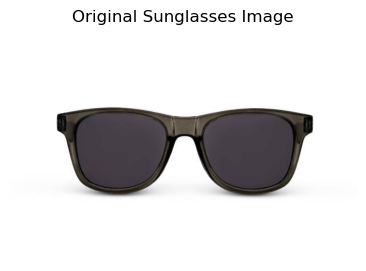

Original sunglasses dimensions: (408, 612, 3)


In [59]:
glassOriginal = cv2.imread('sunglass.jpg', cv2.IMREAD_COLOR)

if glassOriginal is None:
    raise FileNotFoundError("Could not find 'sunglass.jpg'. Keep it in the notebook folder.")

plt.figure(figsize=(7, 3))
plt.imshow(cv2.cvtColor(glassOriginal, cv2.COLOR_BGR2RGB))
plt.title("Original Sunglasses Image")
plt.axis("off")
plt.show()

print("Original sunglasses dimensions:", glassOriginal.shape)

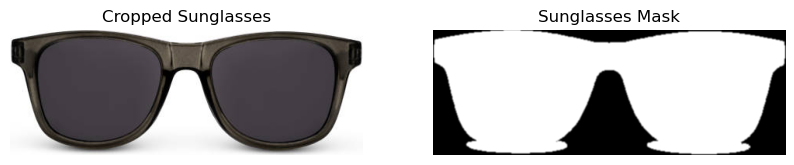

Cropped sunglasses dimensions: (162, 455, 3)


In [60]:
# Convert to grayscale and identify the near-white background.
gray_glass = cv2.cvtColor(glassOriginal, cv2.COLOR_BGR2GRAY)

# Dark sunglass pixels become white in the mask; near-white background becomes black.
_, raw_mask = cv2.threshold(gray_glass, 225, 255, cv2.THRESH_BINARY_INV)

# Remove isolated noise and soften the mask edges slightly.
kernel = np.ones((3, 3), np.uint8)
raw_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, kernel)
raw_mask = cv2.GaussianBlur(raw_mask, (3, 3), 0)

# Crop to the actual sunglass content so white margins do not affect alignment.
coords = cv2.findNonZero(raw_mask)
if coords is None:
    raise ValueError("Could not detect the sunglasses. Check that sunglass.jpg has dark glasses on a light background.")

x, y, w, h = cv2.boundingRect(coords)
glassBGR = glassOriginal[y:y+h, x:x+w].copy()
glassMask1 = raw_mask[y:y+h, x:x+w].copy()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(glassBGR, cv2.COLOR_BGR2RGB))
plt.title("Cropped Sunglasses")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(glassMask1, cmap="gray")
plt.title("Sunglasses Mask")
plt.axis("off")
plt.show()

print("Cropped sunglasses dimensions:", glassBGR.shape)

In [61]:
# Sunglasses width on the 400 x 400 face.
# Height is calculated automatically to preserve the original aspect ratio.
target_width = 175
target_height = max(1, int(glassBGR.shape[0] * target_width / glassBGR.shape[1]))

glassBGR = cv2.resize(glassBGR, (target_width, target_height), interpolation=cv2.INTER_AREA)
glassMask1 = cv2.resize(glassMask1, (target_width, target_height), interpolation=cv2.INTER_AREA)

# Position for the supplied front-facing portrait:
# x=105 centres the glasses over both eyes; y=88 places the bridge at the eye line.
# Adjust x and y slightly if your photo differs.
x1 = 105
y1 = 88

# Keep the overlay fully inside the face image.
x1 = max(0, min(x1, resized_faceImage.shape[1] - target_width))
y1 = max(0, min(y1, resized_faceImage.shape[0] - target_height))
x2 = x1 + target_width
y2 = y1 + target_height

print("Sunglasses size:", target_width, "x", target_height)
print("Sunglasses position: x =", x1, ", y =", y1)

Sunglasses size: 175 x 62
Sunglasses position: x = 105 , y = 88


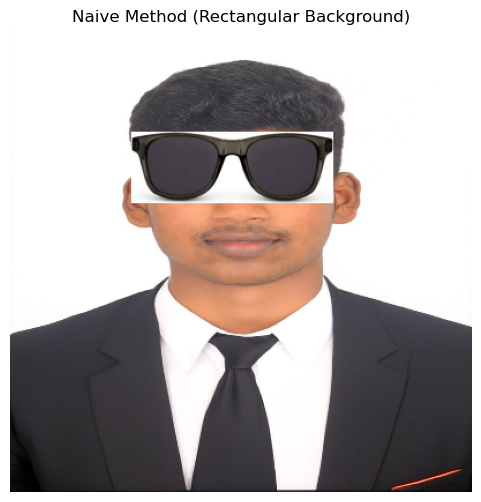

In [62]:
# Naive method: directly copy the rectangular sunglasses image.
# This intentionally demonstrates why a mask is needed.
faceWithGlassesNaive = resized_faceImage.copy()
faceWithGlassesNaive[y1:y2, x1:x2] = glassBGR

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("Naive Method (Rectangular Background)")
plt.axis("off")
plt.show()

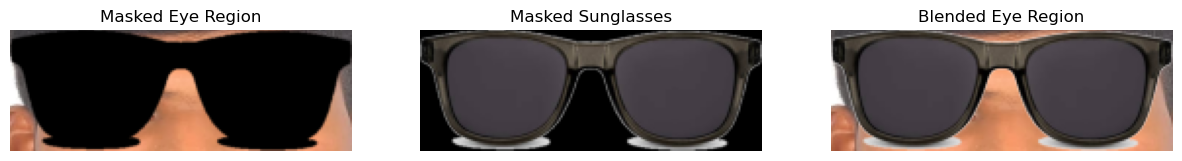

In [63]:
# Convert the single-channel mask to a 3-channel floating-point mask (0 to 1).
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1)).astype(np.float32) / 255.0

# Extract the matching eye-region ROI from the face.
faceWithGlassesArithmetic = resized_faceImage.copy()
eyeROI = faceWithGlassesArithmetic[y1:y2, x1:x2].astype(np.float32)
glass_float = glassBGR.astype(np.float32)

# Arithmetic blending:
# Result = (Face ROI x (1 - Mask)) + (Sunglasses x Mask)
maskedEye = cv2.multiply(eyeROI, 1.0 - glassMask)
maskedGlass = cv2.multiply(glass_float, glassMask)
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Convert back to 8-bit image.
maskedEye = np.clip(maskedEye, 0, 255).astype(np.uint8)
maskedGlass = np.clip(maskedGlass, 0, 255).astype(np.uint8)
eyeRoiFinal = np.clip(eyeRoiFinal, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(maskedEye, cv2.COLOR_BGR2RGB))
plt.title("Masked Eye Region")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(maskedGlass, cv2.COLOR_BGR2RGB))
plt.title("Masked Sunglasses")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(eyeRoiFinal, cv2.COLOR_BGR2RGB))
plt.title("Blended Eye Region")
plt.axis("off")

plt.show()

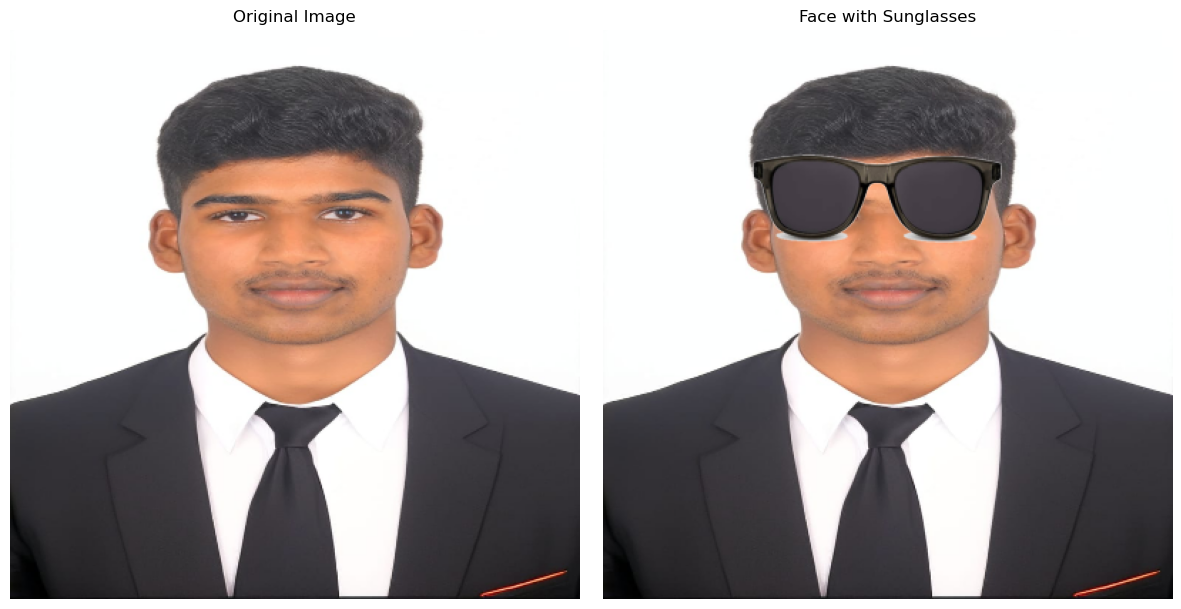

Saved final output as sunglasses_output.jpg


In [64]:
# Place the blended eye region back into the face image.
faceWithGlassesArithmetic[y1:y2, x1:x2] = eyeRoiFinal

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(resized_faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB))
plt.title("Face with Sunglasses")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the final result in the notebook folder.
cv2.imwrite("sunglasses_output.jpg", faceWithGlassesArithmetic)
print("Saved final output as sunglasses_output.jpg")